In [19]:
def temp_c_to_f(temp_c):
    """Convert temperature from Celsius to Fahrenheit."""
    return round((1.8 * temp_c)+ 32, 2)

# ask user for an input temperature in celsius 
temp_c = float(input("Enter the temperature in celsius: \n"))

#convert temperature from celsius to farenheit 
temp_f = temp_c_to_f(temp_c)

#return the fahrenheit temperature to the user 
print(f"Temperature in Fahrenheit: {temp_f} F")


Temperature in Fahrenheit: 53.6 F


File contains: (300, 2)


<Axes: xlabel='temp_c', ylabel='temp_f'>

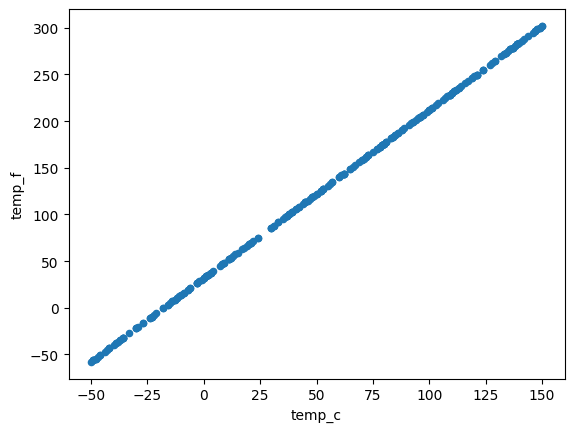

In [22]:
import pandas as pd 

data_file="celsius_farinette_dataset.csv"
data= pd.read_csv(data_file, header=None)
data.columns = ["temp_c", "temp_f"]

print(f"File contains: {data.shape}")
data.describe()

data.plot(kind="scatter", x="temp_c", y="temp_f")



In [24]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score  # <- utilisé pour classification, pas utile ici

# Suppose que les données sont déjà chargées dans 'data'
# Exemple : data = pd.read_csv("celsius_farinette_dataset.csv")

X = np.array(data["temp_c"]).reshape((-1, 1))  # Variable d'entrée : Celsius
y = np.array(data["temp_f"])                  # Variable cible : Farinette

# 1. Choisir un modèle
model = LinearRegression()

# 2. Diviser les données en entraînement (70%) et test (30%)
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.3)

# 3. Entraîner le modèle sur les données d'entraînement
model.fit(x_train, y_train)

# Évaluer sur l'entraînement
r2_train = model.score(x_train, y_train)
print("Score on Training set:", r2_train)

# 4. Évaluer sur les données non vues (test)
r2_test = model.score(x_test, y_test)
print("Score on Test set:", r2_test)


Score on Training set: 1.0
Score on Test set: 1.0


In [34]:
print("Coefficeint of determinaton:", r2_test)
print("Intercept:", model.intercept_)
print("Slope:", model.coef_[0])

Coefficeint of determinaton: 1.0
Intercept: 31.999999999999986
Slope: 1.8000000000000005


In [39]:
print("This is ML system that:\nTemperature in F {} X temperature in c + {}".format(round(model.coef_[0], 2), round(model.intercept_), 2 ))

This is ML system that:
Temperature in F 1.8 X temperature in c + 32


In [45]:
# Use the model to predict a response vs the traditional system:

temp_c = float(input("Enter the Temperature in Celsius :\n"))
# Traditional system response:
print("Software: Temperature in Fahrenheit :", temp_c_to_f(temp_c), "F")
# ML model response:
print("ML Temperature in Fahrenheit :", round(model.predict(np.array(temp_c).reshape(1,-1))[0],2), "F")

Software: Temperature in Fahrenheit : 73.4 F
ML Temperature in Fahrenheit : 73.4 F
